<a href="https://colab.research.google.com/github/bavucadoz/PCVK-Ganjil-2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
NAMA = 'Arya Bayu Samodra'
NIM = '244107020162'
ABSEN = '03'
print(ABSEN, NAMA, NIM)

03 Arya Bayu Samodra 244107020162




---

# **D. PRAKTIKUM MORFOLOGI**



---



In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

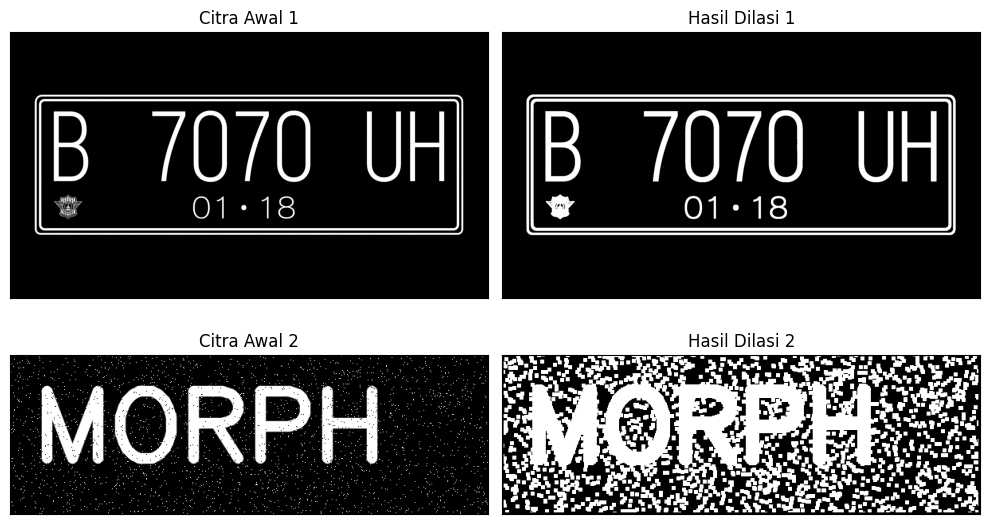

In [4]:
# Fungsi Dilatasi Cross 3x3 Tanpa Library

def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  #Generate structure element dilasi (SED)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
w = 5
plt.figure(figsize=(10, 6))

# Perulangan untuk memproses tiap citra
for i, path in enumerate(path_gambar):
    img_d = cv2.imread(path, 0)
    ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
    imgD = dilasi_citra(thresh, w)

    plt.subplot(len(path_gambar), 2, i * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title(f'Citra Awal {i+1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(len(path_gambar), 2, i * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title(f'Hasil Dilasi {i+1}')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Kernel:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


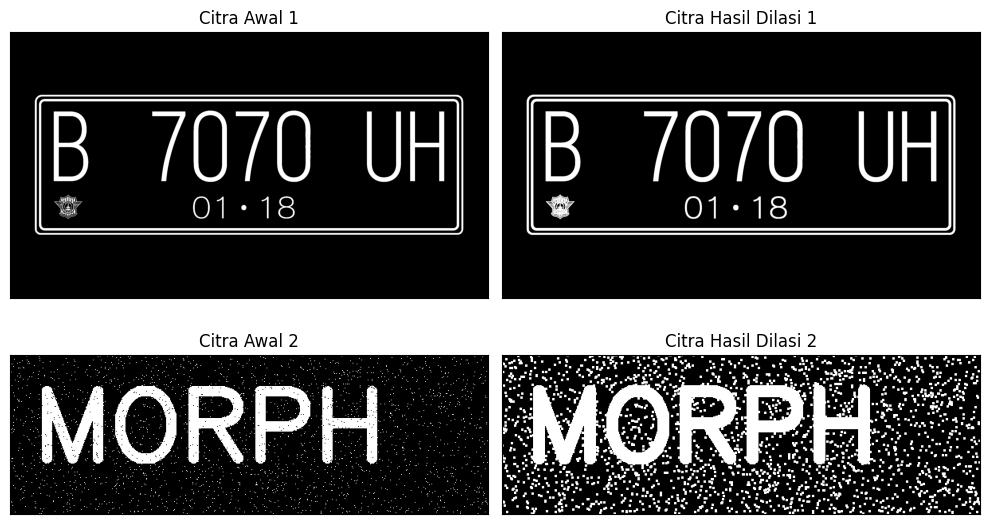

In [5]:
# Dilasi Square 3x3 Dengan Library

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
kernel = np.ones((3, 3), np.uint8)
print("Kernel:")
print(kernel)

plt.figure(figsize=(10, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)

    ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
    dilasi = cv2.dilate(thresh, kernel, iterations=1)

    plt.subplot(len(path_gambar), 2, i * 2 + 1)
    plt.imshow(thresh, cmap='gray')
    plt.title(f'Citra Awal {i+1}')
    plt.xticks([]), plt.yticks([])

    plt.subplot(len(path_gambar), 2, i * 2 + 2)
    plt.imshow(dilasi, cmap='gray')
    plt.title(f'Citra Hasil Dilasi {i+1}')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

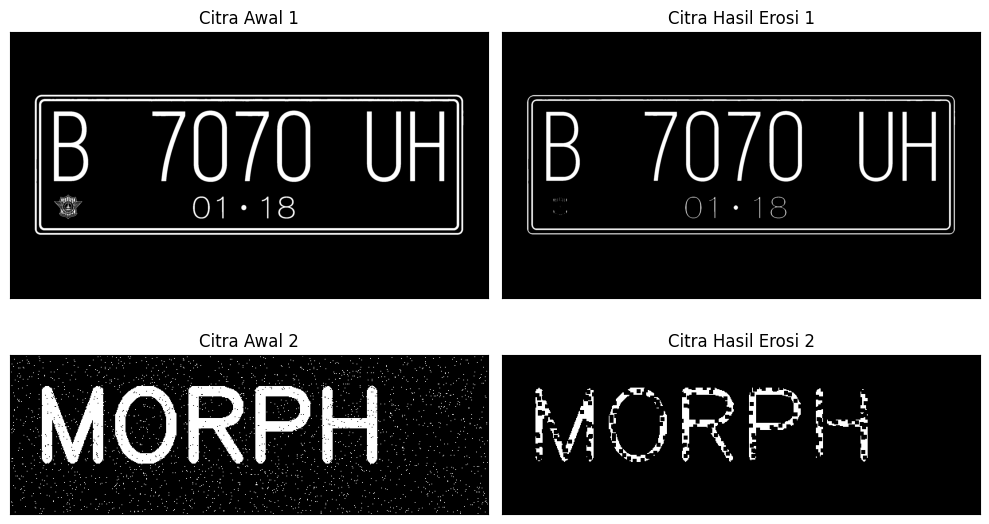

In [24]:
# Erosi Square 5x5 Tanpa Library

def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
k = 5
plt.figure(figsize=(10, 6))

for i, path in enumerate(path_gambar):
    img_e = cv2.imread(path, 0)

    # Thresholding ke nilai biner murni (0 dan 255)
    ret1, thresh1 = cv2.threshold(img_e, 175, 255, cv2.THRESH_BINARY)
    imgE = erosi_citra(thresh1, k)

    # Subplot Citra Awal (Biner)
    plt.subplot(len(path_gambar), 2, i * 2 + 1)
    plt.imshow(thresh1, cmap='gray')
    plt.title(f'Citra Awal {i+1}')
    plt.xticks([]), plt.yticks([])

    # Subplot Citra Hasil Erosi
    plt.subplot(len(path_gambar), 2, i * 2 + 2)
    plt.imshow(imgE, cmap='gray')
    plt.title(f'Citra Hasil Erosi {i+1}')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

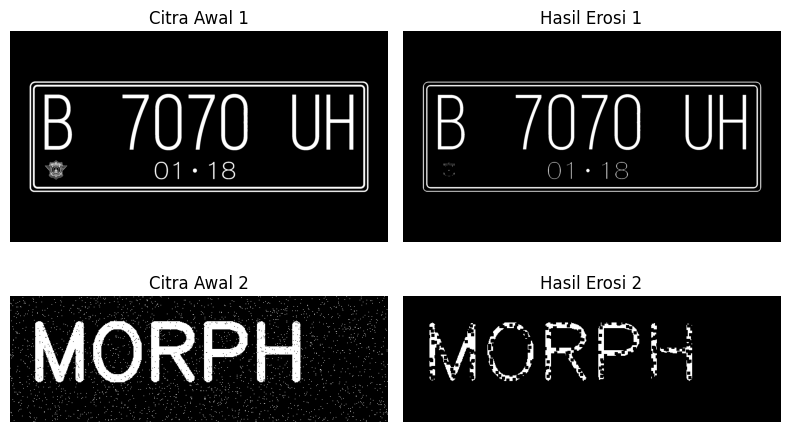

In [25]:
# Erosi Square 5x5 dengan Library

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
kernel = np.ones((5, 5), np.uint8)
plt.figure(figsize=(8, 5))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
    erosion = cv2.erode(thresh, kernel)

    # Inner loop untuk plotting
    for j, (citra, judul) in enumerate([(thresh, f'Citra Awal {i+1}'), (erosion, f'Hasil Erosi {i+1}')]):
        ax = plt.subplot(len(path_gambar), 2, i * 2 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

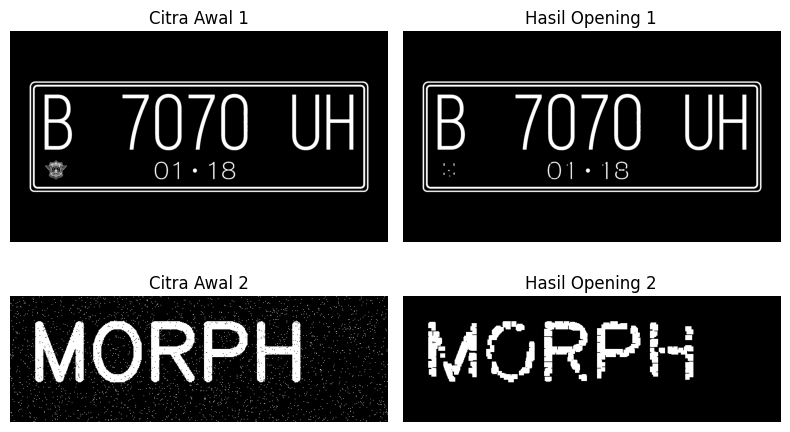

In [26]:
# Operasi Opening Square 3x3 Menggunakan tanpa Library Morphology

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
k = 7
plt.figure(figsize=(8, 5))

for i, path in enumerate(path_gambar):
    img_o = cv2.imread(path, 0)
    _, thresho = cv2.threshold(img_o, 127, 255, cv2.THRESH_BINARY)

    # Opening
    imgO = dilasi_citra(erosi_citra(thresho, k), k)

    # Plotting
    for j, (citra, judul) in enumerate([(thresho, f'Citra Awal {i+1}'), (imgO, f'Hasil Opening {i+1}')]):
        ax = plt.subplot(len(path_gambar), 2, i * 2 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

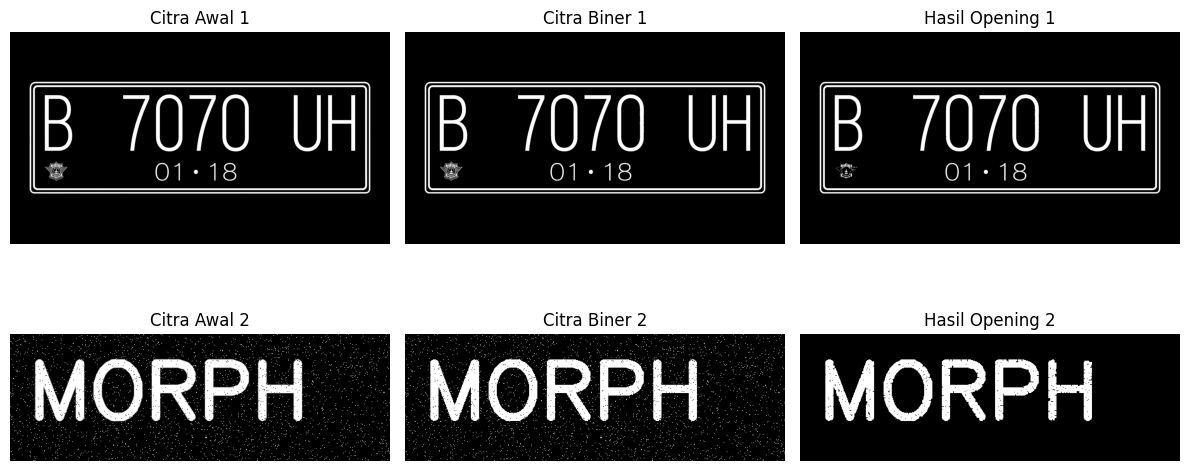

In [27]:
# Operasi Opening Square 3x3 Menggunakan Library Morphology

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
kernel = np.ones((3, 3), np.uint8)
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
    openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

    tampilan = [
        (img, f'Citra Awal {i+1}'),
        (thresh, f'Citra Biner {i+1}'),
        (openn, f'Hasil Opening {i+1}')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

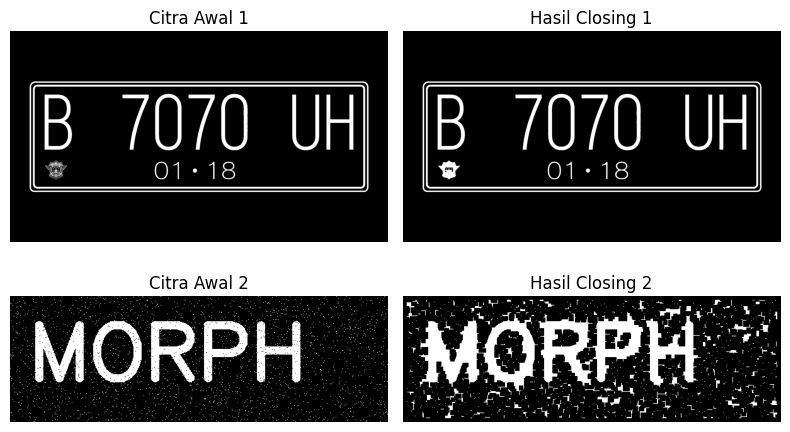

In [28]:
# Operasi Closing Square 3x3 Tanpa dan Menggunakan Library Morphologi

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
k = 7
plt.figure(figsize=(8, 5))

for i, path in enumerate(path_gambar):
    img_c = cv2.imread(path, 0)
    _, threshc = cv2.threshold(img_c, 127, 255, cv2.THRESH_BINARY)

    imgC = erosi_citra(dilasi_citra(threshc, k), k)

    tampilan = [
        (threshc, f'Citra Awal {i+1}'),
        (imgC, f'Hasil Closing {i+1}')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 2, i * 2 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

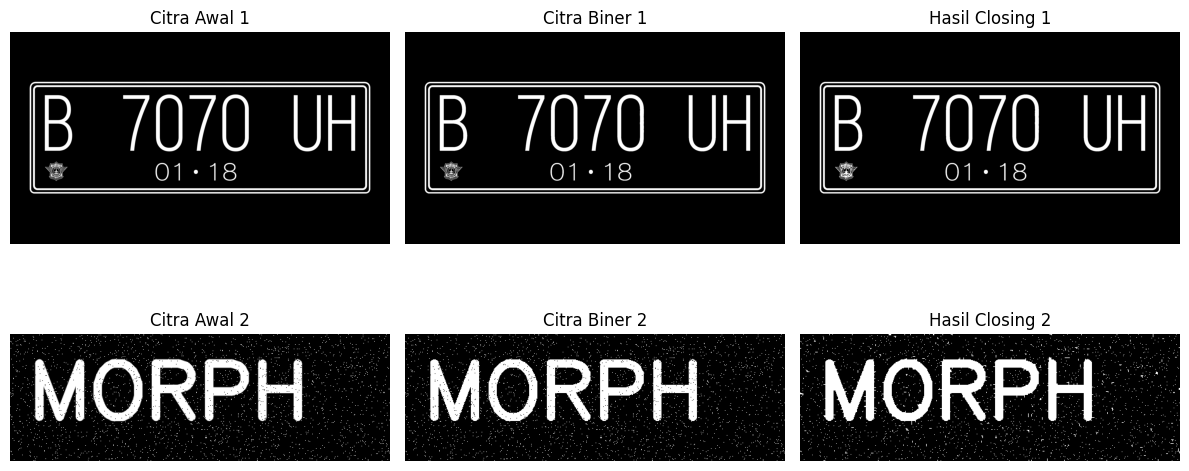

In [29]:
# Operasi Closing Square 3x3 dengan Menggunakan Library Morphologi

path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
kernel = np.ones((3, 3), np.uint8)
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
    closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    tampilan = [
        (img, f'Citra Awal {i+1}'),
        (thresh, f'Citra Biner {i+1}'),
        (closs, f'Hasil Closing {i+1}')
    ]

    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

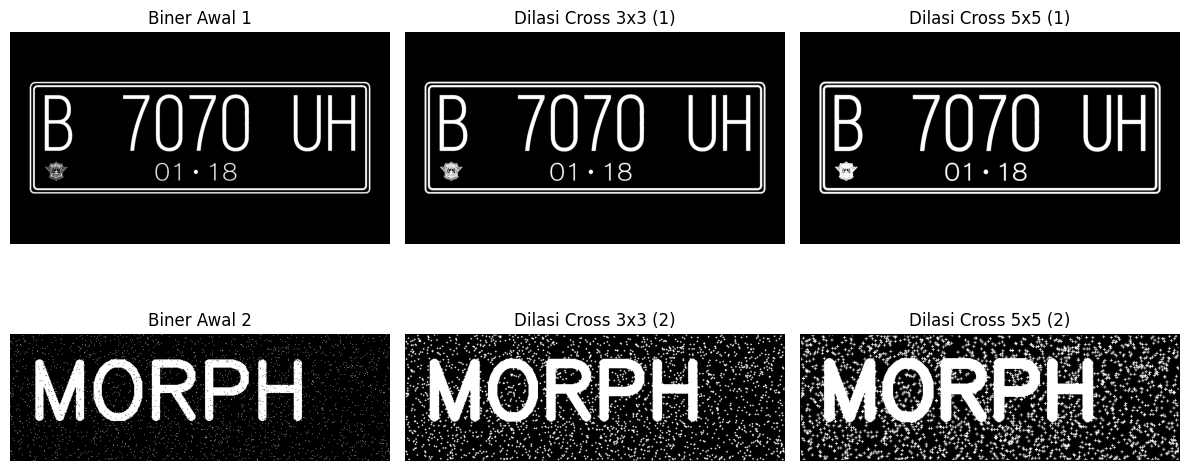

In [32]:
# Operasi Dilasi Structuring Element berbentuk Cross 3 x 3 dan 5 x 5

# Fungsi Dilasi Manual (Menerima Matriks SED Bebas)
def dilasi_citra(F, SED):
    p, q = F.shape
    w = SED.shape[0]
    constant = (w - 1) // 2
    imgD = np.zeros((p, q), dtype=np.uint8)

    for i in range(constant, p - constant):
        for j in range(constant, q - constant):
            temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
            imgD[i, j] = np.max(temp * SED)
    return imgD

# Matriks Structuring Element Cross 3x3 dan 5x5
SED_cross3 = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

SED_cross5 = np.array([
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 1, 1],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0]
], dtype=np.uint8)

# Pemrosesan Multi-Citra
path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

    # Memproses dengan Cross 3x3 dan Cross 5x5
    dilasi_3 = dilasi_citra(thresh, SED_cross3)
    dilasi_5 = dilasi_citra(thresh, SED_cross5)

    # Menampilkan perbandingan per baris
    tampilan = [
        (thresh, f'Biner Awal {i+1}'),
        (dilasi_3, f'Dilasi Cross 3x3 ({i+1})'),
        (dilasi_5, f'Dilasi Cross 5x5 ({i+1})')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

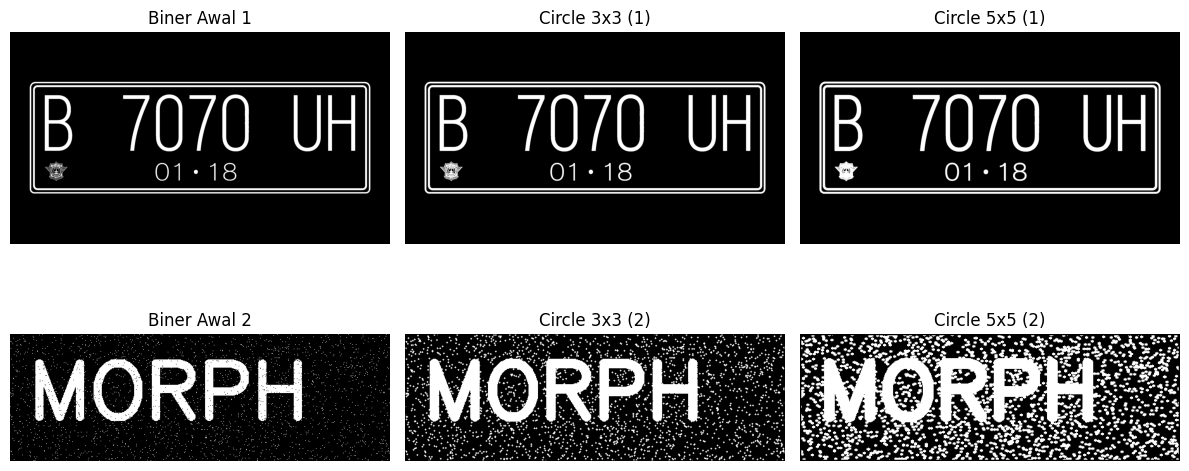

In [33]:
# Operasi Dilasi Structuring Element berbentuk Circular 3 x 3 dan 5 x 5

# Fungsi Dilasi Circular Manual
def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structuring Element berbentuk Circular
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi Manual
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            imgD[i, j] = np.max(temp * SED)
    return imgD

# Pemrosesan Multi-Citra
path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

    # Dilasi Circular dengan ukuran 3x3 dan 5x5
    dilasi_c3 = dilasi_circular(thresh, 3)
    dilasi_c5 = dilasi_circular(thresh, 5)

    tampilan = [
        (thresh, f'Biner Awal {i+1}'),
        (dilasi_c3, f'Circle 3x3 ({i+1})'),
        (dilasi_c5, f'Circle 5x5 ({i+1})')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')
plt.tight_layout()
plt.show()

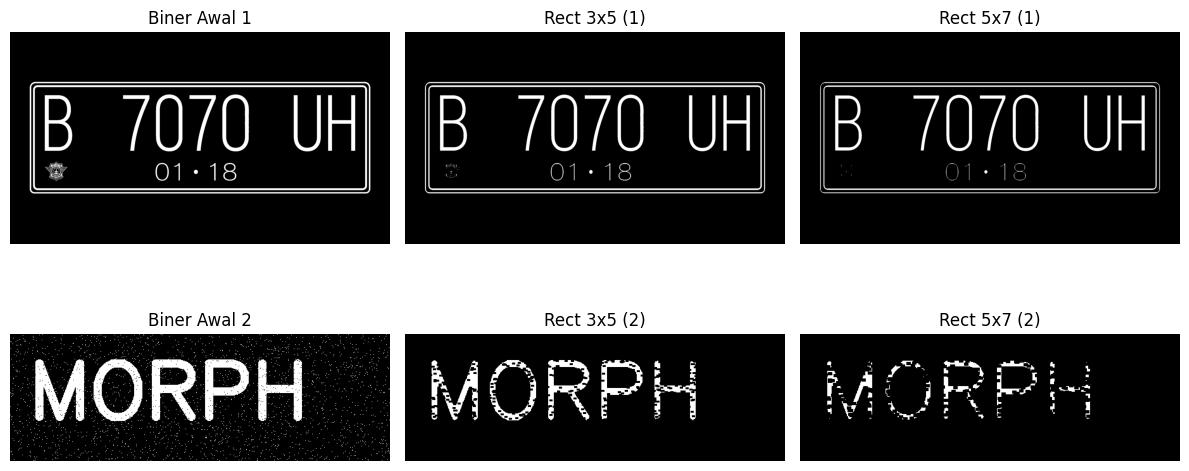

In [34]:
# Operasi Erosi Structuring Element berbentuk Rectangle 3 x 5 dan 5 x 7

# Fungsi Erosi Rectangle Manual
def erosi_rectangle(F, p, l):
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)

    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))

    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    # Proses Erosi Manual
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1 : i + constant1 + 1, j - constant2 : j + constant2 + 1]
            imgE[i, j] = np.min(temp * SE)

    return imgE

# Pemrosesan Multi-Citra
path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

    # Erosi Rectangle: 3x5 (p=5, l=3) dan 5x7 (p=7, l=5)
    erosi_3x5 = erosi_rectangle(thresh, p=5, l=3)
    erosi_5x7 = erosi_rectangle(thresh, p=7, l=5)


    tampilan = [
        (thresh, f'Biner Awal {i+1}'),
        (erosi_3x5, f'Rect 3x5 ({i+1})'),
        (erosi_5x7, f'Rect 5x7 ({i+1})')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

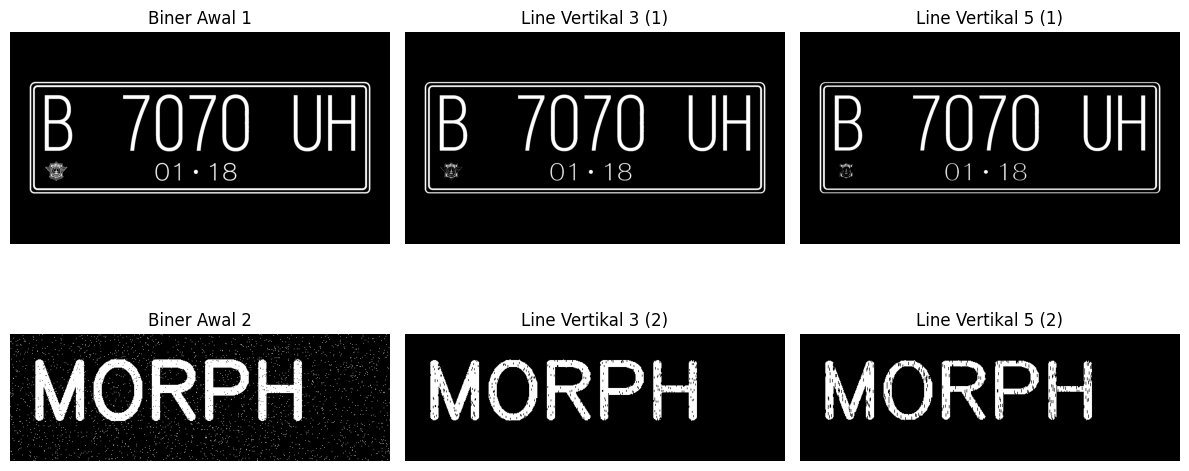

In [35]:
# Operasi Erosi Structuring Element berbentuk Line vertikal 3 dan 5

# Fungsi Erosi Line Vertikal Manual
def erosi_line_vertikal(F, k):
    m, n = F.shape
    imgE = np.zeros((m, n), dtype=np.uint8)

    # SE berbentuk Line Vertikal (lebar = 1, tinggi = k)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (1, k))
    constant = (k - 1) // 2

    # Proses Erosi Manual
    for i in range(constant, m - constant):
        for j in range(0, n):
            # Slicing vertikal sepanjang k dan horizontal sebesar 1 piksel
            temp = F[i - constant : i + constant + 1, j : j + 1]
            imgE[i, j] = np.min(temp * SE)
    return imgE

# Pemrosesan Multi-Citra
path_gambar = [
    '/content/drive/MyDrive/PCVK/Images/platnomor2.jpg',
    '/content/drive/MyDrive/PCVK/Images/noisy_text.png'
]
plt.figure(figsize=(12, 6))

for i, path in enumerate(path_gambar):
    img = cv2.imread(path, 0)
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

    # Erosi Line Vertikal ukuran 3 dan 5
    erosi_v3 = erosi_line_vertikal(thresh, k=3)
    erosi_v5 = erosi_line_vertikal(thresh, k=5)

    tampilan = [
        (thresh, f'Biner Awal {i+1}'),
        (erosi_v3, f'Line Vertikal 3 ({i+1})'),
        (erosi_v5, f'Line Vertikal 5 ({i+1})')
    ]
    for j, (citra, judul) in enumerate(tampilan):
        ax = plt.subplot(len(path_gambar), 3, i * 3 + j + 1)
        ax.imshow(citra, cmap='gray')
        ax.set_title(judul)
        ax.axis('off')

plt.tight_layout()
plt.show()

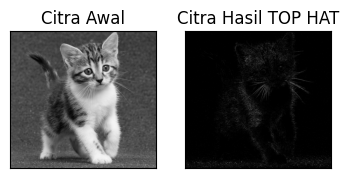

In [19]:
# Transformasi Top-hat dengan structuring element 3 × 3

filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

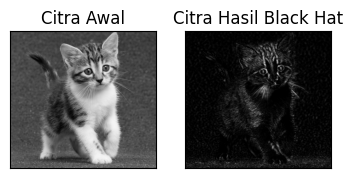

In [15]:
# Transformasi Black-hat dengan structuring element 3 × 3.

filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

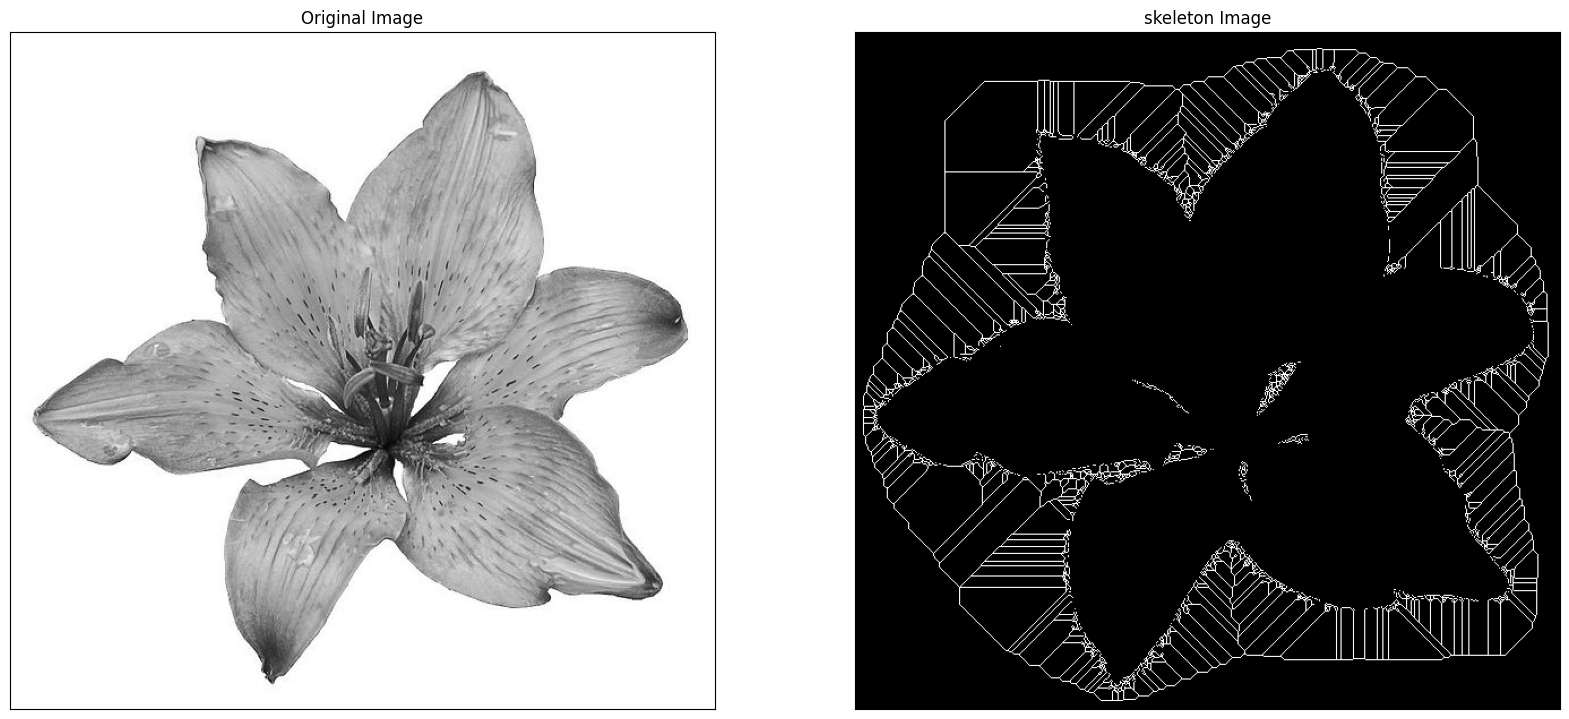

In [21]:
# Skeleton pada Citra Biner

import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg',0)
binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20,20))

plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()

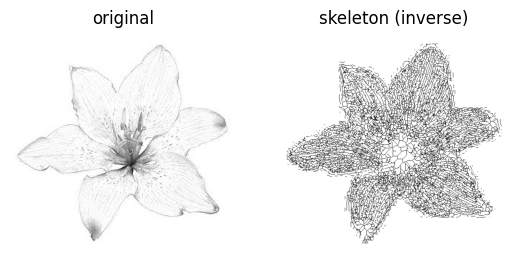

In [22]:
# Skeleton pada Citra Hasil Inversi

from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use :
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

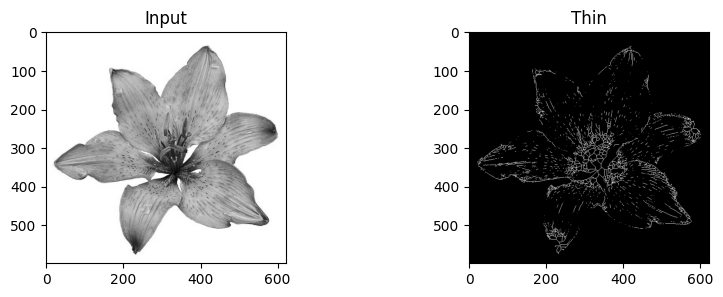

In [23]:
# Thinning dengan morphology.thin()

from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

**Perbandingan Hasil Skeleton pada Biner dan Thinning:**


*   `Skeleton` menggunakan threshold img > threshold, yang menyebabkan area latar belakang berintensitas terang terpilih sebagai objek putih. Akibatnya, kerangka yang terbentuk berada di luar kelopak bunga. Sedangkan, `Thinning` menggunakan pengambangan image < 0.5, yang secara tepat mengisolasi bunga sebagai objek putih utama. Hasil penipisan berada di dalam area bunga, mengekstrak kontur dan pola serat di dalam kelopak.
*   `Skeleton` berfokus pada penemuan sumbu simetri tengah dari wilayah biner luas, menghasilkan jaringan garis utama yang topologinya terhubung secara simetris. Sedangkan `Thinning` mengikis piksel batas objek secara iteratif dari luar ke dalam hingga tersisa garis selebar 1 piksel, sehingga lebih sensitif terhadap detail tepi, urat bunga, dan batas kelopak yang halus.



